In [38]:
import torch
import lightning as L
from lightning.pytorch.loggers import TensorBoardLogger
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping
from lightning.pytorch.utilities.model_summary import ModelSummary

from matplotlib import pyplot as plt
import numpy as np
import importlib
from data_functions import dataset, utils_data
from src import LTAE, lightning_module, utils_model, metrics

PATH_TO_DATA_s2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/s2"
PATH_TO_DATA_label = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"
PATH_TO_OSO_CLASSES = "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"

In [26]:
from src.metrics import FocalLoss, alpha_weights
from data_functions import dataset
import torch.nn.functional as F

In [27]:
dt = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    norm=True,
    folds=None,
)


In [28]:
count = alpha_weights(dt)

In [51]:
count_bis = count.copy()

In [67]:
count_bis

array([2.1730000e+03, 8.4818200e+05, 1.9274550e+06, 7.0392900e+05,
       1.2956600e+05, 8.3505300e+05, 5.6405550e+06, 5.3720600e+05,
       2.1233700e+05, 6.8763400e+05, 2.9046390e+06, 1.1863400e+05,
       9.2840300e+05, 1.2217791e+07, 4.4714300e+05, 1.4098600e+06,
       1.4515751e+07, 5.3538920e+06, 3.1168000e+06, 2.3764100e+06,
       1.2730390e+06, 1.3403700e+05, 2.9437200e+05, 1.5909660e+06,
       1.0482900e+05])

In [68]:
count_bis.max() /count_bis[4]

np.float64(112.03364308537734)

In [52]:
freqs = 1/count_bis
print(freqs)

[4.60193281e-04 1.17899224e-06 5.18818857e-07 1.42059782e-06
 7.71807419e-06 1.19752878e-06 1.77287519e-07 1.86148330e-06
 4.70949481e-06 1.45426201e-06 3.44276862e-07 8.42928671e-06
 1.07711845e-06 8.18478561e-08 2.23642101e-06 7.09290284e-07
 6.88906830e-08 1.86780010e-07 3.20841889e-07 4.20802808e-07
 7.85521889e-07 7.46062654e-06 3.39706222e-06 6.28548944e-07
 9.53934503e-06]


In [63]:
freqs[0] = 0
alpha_test =  freqs / freqs.sum()
print(alpha_test)

[0.         0.02108235 0.00927735 0.02540266 0.13801203 0.02141381
 0.0031702  0.03328642 0.08421361 0.02600463 0.00615624 0.15072969
 0.01926067 0.00146358 0.03999093 0.01268329 0.00123188 0.00333994
 0.00573719 0.00752466 0.01404644 0.13340843 0.06074513 0.0112395
 0.17057938]


In [64]:
np.save("alpha_weights.npy", alpha_test)

In [48]:
test = 1 / np.log(1 + count_bis)
test[0] = 0
test = test / test.sum()
print(test*100)


[0.         4.16876245 3.93230322 4.22647971 4.83413041 4.17353191
 3.66068527 4.31306347 4.63944735 4.23384428 3.82393806 4.87060072
 4.14134615 3.48729928 4.37389518 4.01915045 3.45085428 3.67300905
 3.80590882 3.87621843 4.0483381  4.82023911 4.51909412 3.98513624
 4.92272396]


In [61]:
inputs = torch.rand([1,25,8,8])
targets = torch.randint(0, 25, (1, 8, 8))
gamma = 2
alpha = torch.rand(25)
alpha = torch.from_numpy(alpha_test*10)
print(targets)
alpha_weights = alpha[targets]
print(alpha_weights)
ce_loss = F.cross_entropy(inputs, targets.long(), reduction="none", ignore_index=0)  # Sortie : (b, h, w)
pt = torch.exp(-ce_loss)
focal_loss = alpha_weights * (1 - pt) ** gamma * ce_loss

tensor([[[19, 13,  3,  7, 23, 14, 11,  2],
         [ 2, 22, 14,  4,  8,  6, 14, 13],
         [ 0, 20, 21, 10, 22, 22, 20, 20],
         [23, 22, 23,  3,  7,  7,  7, 20],
         [ 6,  3,  9, 11, 20, 20, 22, 24],
         [21, 11, 21, 17, 12,  5, 12,  9],
         [ 2, 13, 15,  5, 22, 17,  0,  9],
         [22, 10, 24, 18, 10,  4,  3,  8]]])
tensor([[[0.0752, 0.0146, 0.2540, 0.3329, 0.1124, 0.3999, 1.5073, 0.0928],
         [0.0928, 0.6075, 0.3999, 1.3801, 0.8421, 0.0317, 0.3999, 0.0146],
         [0.0000, 0.1405, 1.3341, 0.0616, 0.6075, 0.6075, 0.1405, 0.1405],
         [0.1124, 0.6075, 0.1124, 0.2540, 0.3329, 0.3329, 0.3329, 0.1405],
         [0.0317, 0.2540, 0.2600, 1.5073, 0.1405, 0.1405, 0.6075, 1.7058],
         [1.3341, 1.5073, 1.3341, 0.0334, 0.1926, 0.2141, 0.1926, 0.2600],
         [0.0928, 0.0146, 0.1268, 0.2141, 0.6075, 0.0334, 0.0000, 0.2600],
         [0.6075, 0.0616, 1.7058, 0.0574, 0.0616, 1.3801, 0.2540, 0.8421]]],
       dtype=torch.float64)


In [62]:
print(focal_loss.mean())
print(ce_loss.mean())

tensor(1.3251, dtype=torch.float64)
tensor(3.1671)


In [2]:
batch_size = 2

dl_train, dl_val, dl_test = dataset.get_loaders(
    path_s2=PATH_TO_DATA_s2,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    folds_train=[1],
    folds_val=[2],
    folds_test=[3],
    batch_size=batch_size,
    num_worker=4,
    norm=True,
    shuffle=True,
)

In [3]:
(x, dates, mask), y = dl_val.__iter__().__next__()
print(x.shape)
print(dates.shape)
print(mask.shape)
print(y.shape)

torch.Size([2, 10, 148, 128, 128])
torch.Size([2, 148])
torch.Size([2, 148, 128, 128])
torch.Size([2, 128, 128])


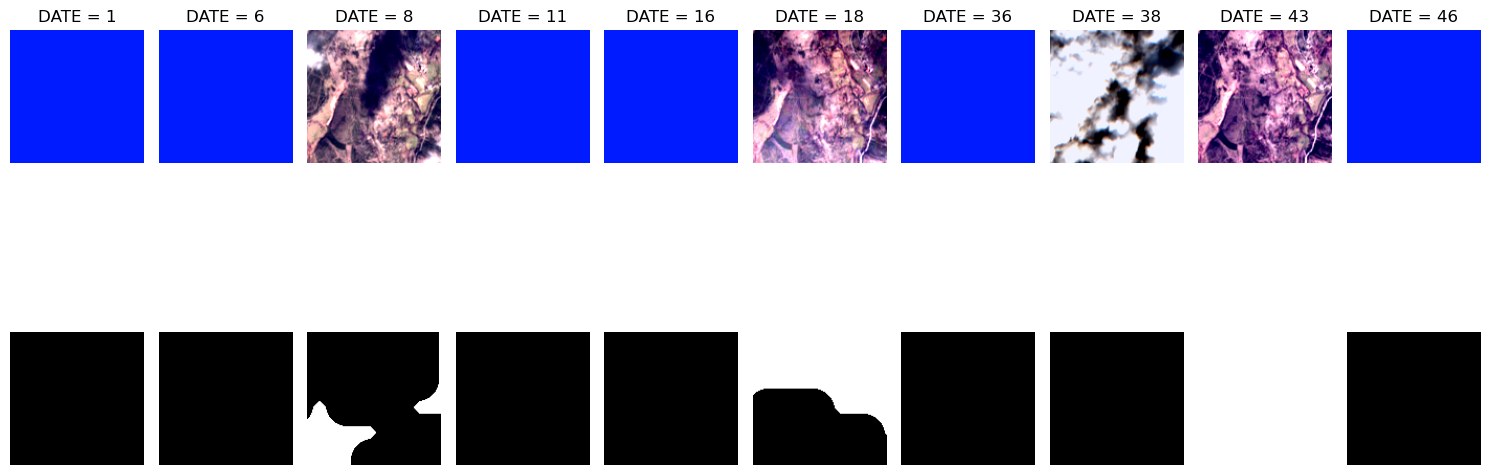

In [5]:
idx_batch = 0
lenght, first_date = 10, 0
fig, axes1 = plt.subplots(2,lenght, figsize=(15,8))
for t in range(lenght):
    # Affichage de l'image RGB
    axes1[0, t].imshow(utils_data.array_to_RGB(x[idx_batch, :,first_date + t, :, :], norm=True))
    axes1[0, t].set_title(f"DATE = {dates[idx_batch, first_date + t].numpy()}")
    axes1[0, t].axis("off")
    # Affichage du masque
    axes1[1, t].imshow(
        mask[idx_batch, first_date + t, :, :], cmap="Greys", vmin=0, vmax=1
    )
    axes1[1, t].axis("off")
plt.tight_layout()

In [6]:
LTAE_encoder = LTAE.LTAE2d(
    in_channels=10,
    n_head=16,
    d_k=16,
    d_model=128,
    T=1000,
    return_att=False,
    positional_encoding=True,
)

MLP_Decoder = utils_model.MLPDecoder(mlp=[128, 64, 25], dropout=0.2)

In [7]:
importlib.reload(lightning_module)

classifier = lightning_module.classifier(LTAE_encoder, MLP_Decoder, batch_size=batch_size)
summary = ModelSummary(classifier, max_depth=-1)
print(summary)

   | Name                                      | Type                      | Params | Mode  | FLOPs
---------------------------------------------------------------------------------------------------------
0  | encoder                                   | LTAE2d                    | 34.7 K | train | 0    
1  | encoder.inconv                            | Conv1d                    | 1.4 K  | train | 0    
2  | encoder.positional_encoder                | PositionalEncoder         | 0      | train | 0    
3  | encoder.attention_heads                   | MultiHeadAttention        | 33.3 K | train | 0    
4  | encoder.attention_heads.fc1_k             | Linear                    | 33.0 K | train | 0    
5  | encoder.attention_heads.attention         | ScaledDotProductAttention | 0      | train | 0    
6  | encoder.attention_heads.attention.dropout | Dropout                   | 0      | train | 0    
7  | encoder.attention_heads.attention.softmax | Softmax                   | 0      | train | 

In [8]:
trainer = L.Trainer(
    max_epochs=1, profiler="simple", limit_train_batches=1, limit_val_batches=1, limit_test_batches=1
)
trainer.fit(model=classifier, train_dataloaders=dl_train, val_dataloaders=dl_val)
trainer.test(model=classifier, dataloaders=dl_test)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1)` was configured so 1 batch per epoch will be used.
`Trainer(limit_val_batches=1)` was configured so 1 batch will be used.
`Trainer(limit_test_batches=1)` was configured so 1 batch will be used.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name           | Type                      | Params | Mode  | FLOPs
-----------------------------------------------------------------------------
0 | encoder        | LTAE2d                    | 34.7 K | train | 0    
1 | decoder        | MLPDecoder                | 10.0 K | train | 0    
2 | loss_fn        | CrossEntropyLoss       

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/loops/fit_loop.py:317: The number of training batches (1) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=1` reached.
FIT Profiler Report

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|  Action                                                                                                                                                         	|  Mean duration (s)	|  Num calls      	|  Total time (s) 	|  Percentage %   	|
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|  Total                                                                                                                                                   

Testing: |          | 0/? [00:00<?, ?it/s]

/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.12/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: 475 NaN values found in confusion matrix have been replaced with zeros.
  warnings.warn(*args, **kwargs)
TEST Profiler Report

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|  Action                                                                                                                                                         	|  Mean duration (s)	|  Num calls      	|  Total time (s) 	|  Percentage %   	|
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Confusion Matrix:
 tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.00

[{'test_accuracy': 0.163055419921875}]

torch.Size([10, 10])


/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.12/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: 10 NaN values found in confusion matrix have been replaced with zeros.
  warnings.warn(*args, **kwargs)


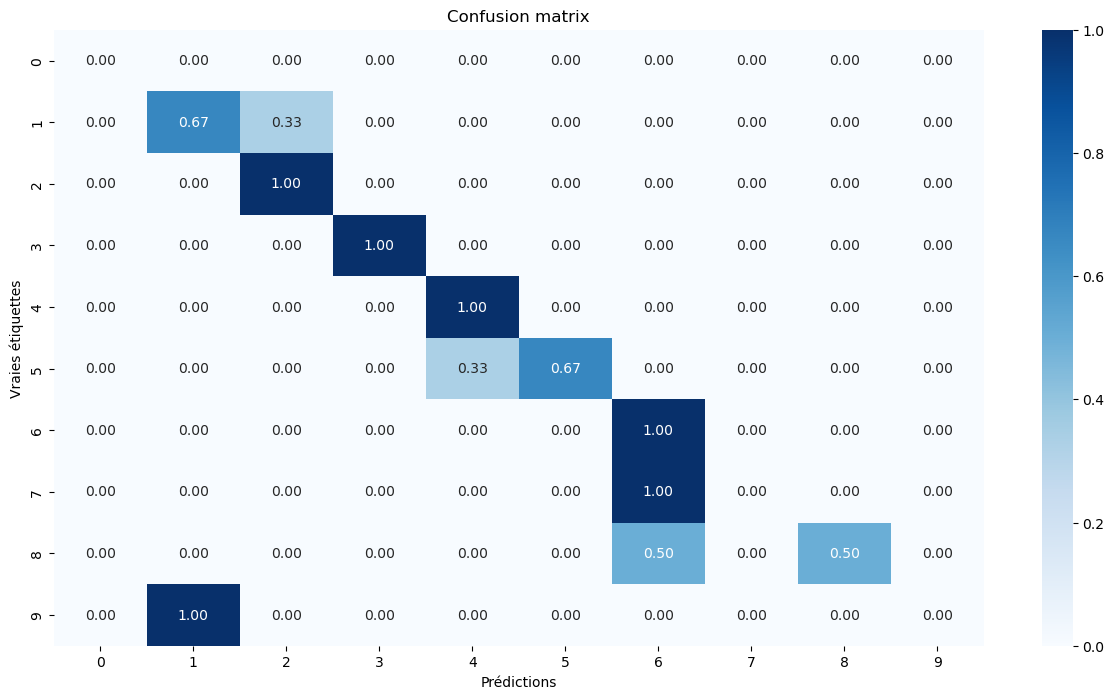

In [22]:
from torchmetrics.classification import MulticlassF1Score, MulticlassConfusionMatrix

f = MulticlassF1Score(num_classes=10,ignore_index=0)
cm = MulticlassConfusionMatrix(num_classes=10,ignore_index=0,normalize="true")
label = torch.Tensor([0,1,2,3,4,5,5,5,6,7,8,8,9,0,1,2,1])
preds = torch.Tensor([1,1,2,3,4,5,4,5,6,6,6,8,1,8,2,2,1])



r_cm = cm(preds,label)

print(r_cm.shape)

fig_cm = metrics.convert_cm_to_figure(r_cm)
